# Caracterización Interactiva y Extracción .OP de Transistores Sky130 (con nf y mult)
---
Este notebook permite **modificar dinámicamente los parámetros de simulación (VGS, VSG, W, L, nf, mult) directamente desde Python**, actualizar el netlist de SPICE, **ejecutar la simulación en NGspice**, extraer la **Tabla de Punto de Operación (.OP)** de los 4 transistores (`Mplvt`, `Mp`, `Mnlvt`, `Mn`) incluyendo la información completa de geometría (`W`, `L`, `nf`, `mult`) y corriente total ($I_{D,	ext{total}}$) usando `spyci`, y visualizar las **Curvas de Caracterización Analógica Interactivas con Plotly**.

In [5]:
print(2.18*2)

4.36


In [1]:
# ==============================================================================
# Encabezado: Modificación Dinámica del Netlist, Simulación en NGspice y Carga (spyci)
# Descripción: Permite al usuario modificar tensiones (VSG, VGS), dimensiones (W, L),
#              dedos (nf) y multiplicidad (mult) desde Python.
#              Actualiza las líneas de instancia (XMplvt, XMp, XMnlvt, XMn),
#              ejecuta NGspice y carga el archivo .raw usando spyci.
# ==============================================================================

import os
import re
import subprocess
import numpy as np
np.complex_ = complex  # Parche de compatibilidad para spyci con NumPy 2.0
from spyci import spyci

# ── 1. Parámetros Configurables desde Python ──────────────────────────────────
VSG_TARGET = 0.6  # Tensión VSG objetivo para evaluar PMOS [V]
VGS_TARGET = 0.6  # Tensión VGS objetivo para evaluar NMOS [V]

# Dimensiones geométricas, dedos (nf) y multiplicidad (mult)
W_MPLVT = 200; L_MPLVT = 0.35; NF_MPLVT = 10; MULT_MPLVT = 2
W_MP    = 1.0; L_MP    = 0.15; NF_MP    = 1; MULT_MP    = 1
W_MNLVT = 1.0; L_MNLVT = 0.35; NF_MNLVT = 1; MULT_MNLVT = 1
W_MN    = 1.0; L_MN    = 0.15; NF_MN    = 1; MULT_MN    = 1

# Rangos de barrido DC para Vgp (PMOS) y Vgn (NMOS)
VGP_START, VGP_STOP, VGP_STEP = 0.0, 1.8, 0.01
VGN_START, VGN_STOP, VGN_STEP = 0.0, 1.8, 0.01

# ── 2. Lectura y Modificación del Netlist SPICE ──────────────────────────────
BASE_NETLIST = '../xschem/caracterizador.spice'
SIM_NETLIST  = '../xschem/caracterizador_sim.spice'
RAW_FILE     = '../xschem/caracterizador.raw'

with open(BASE_NETLIST, 'r') as f:
    spice_content = f.read()

# Función para actualizar W, L, nf y mult en las líneas de instancia del Netlist
def update_instance_full(text, inst_name, w_val, l_val, nf_val, mult_val):
    pattern = r'(' + inst_name + r'\s+.*?L=)[0-9.eE+-]+(\s+W=)[0-9.eE+-]+(\s+nf=)[0-9.eE+-]+.*?(mult=)[0-9.eE+-]+'
    replacement = r'\g<1>' + str(l_val) + r'\g<2>' + str(w_val) + r'\g<3>' + str(nf_val) + r' ... \g<4>' + str(mult_val)
    # Reemplazo seguro campo por campo
    pattern_w_l = r'(' + inst_name + r'\s+.*?L=)[0-9.eE+-]+(\s+W=)[0-9.eE+-]+'
    text = re.sub(pattern_w_l, r'\g<1>' + str(l_val) + r'\g<2>' + str(w_val), text, flags=re.IGNORECASE)
    
    pattern_nf = r'(' + inst_name + r'\s+.*?nf=)[0-9.eE+-]+'
    text = re.sub(pattern_nf, r'\g<1>' + str(nf_val), text, flags=re.IGNORECASE)
    
    pattern_mult = r'(' + inst_name + r'\s+.*?mult=)[0-9.eE+-]+'
    text = re.sub(pattern_mult, r'\g<1>' + str(mult_val), text, flags=re.IGNORECASE)
    return text

# Actualizar instancias de los 4 transistores
spice_content = update_instance_full(spice_content, 'XMplvt', W_MPLVT, L_MPLVT, NF_MPLVT, MULT_MPLVT)
spice_content = update_instance_full(spice_content, 'XMp', W_MP, L_MP, NF_MP, MULT_MP)
spice_content = update_instance_full(spice_content, 'XMnlvt', W_MNLVT, L_MNLVT, NF_MNLVT, MULT_MNLVT)
spice_content = update_instance_full(spice_content, 'XMn', W_MN, L_MN, NF_MN, MULT_MN)

# Reemplazo de parámetros .param
spice_content = re.sub(r'\.param vsg\s*=\s*[0-9.eE+-]+', f'.param vsg = {VSG_TARGET}', spice_content)
spice_content = re.sub(r'\.param vgs\s*=\s*[0-9.eE+-]+', f'.param vgs = {VGS_TARGET}', spice_content)

# Actualización del comando dc en el bloque control
spice_content = re.sub(
    r'dc Vgp\s+[0-9.eE+-]+\s+[0-9.eE+-]+\s+[0-9.eE+-]+\s+Vgn\s+[0-9.eE+-]+\s+[0-9.eE+-]+\s+[0-9.eE+-]+',
    f'dc Vgp {VGP_START} {VGP_STOP} {VGP_STEP} Vgn {VGN_START} {VGN_STOP} {VGN_STEP}',
    spice_content
)

with open(SIM_NETLIST, 'w') as f:
    f.write(spice_content)

print(f"Netlist actualizado dinámicamente en: {SIM_NETLIST}")

# ── 3. Lanzar Simulación en NGspice ───────────────────────────────────────────
print("Ejecutando simulación NGspice...")
cmd_sim = f'export PATH=/foss/tools/xschem/bin:/foss/tools/ngspice/bin:$PATH; cd ../xschem && ngspice -b caracterizador_sim.spice'
result = subprocess.run(cmd_sim, shell=True, capture_output=True, text=True)

if result.returncode == 0:
    print("¡Simulación completada con éxito!")
else:
    print("Error durante la simulación:", result.stderr)

# ── 4. Carga del archivo .raw usando spyci ────────────────────────────────────
print(f"Cargando datos con spyci desde: {RAW_FILE}...")
raw_data = spyci.load_raw(RAW_FILE)['values']
print(f"¡Carga exitosa! Total de puntos procesados: {len(raw_data)}")

Netlist actualizado dinámicamente en: ../xschem/caracterizador_sim.spice
Ejecutando simulación NGspice...
¡Simulación completada con éxito!
Cargando datos con spyci desde: ../xschem/caracterizador.raw...
¡Carga exitosa! Total de puntos procesados: 32761


In [2]:
# ==============================================================================
# Encabezado: Extracción de la Tabla de Punto de Operación (.OP) con Geometry & Total Current
# Descripción: Extrae los parámetros unitarios y calcula la corriente total multiplicada
#              (Id_total = mult * Id_unit) junto con W, L, nf y mult para cada transistor.
# ==============================================================================

import pandas as pd

# Definición de cortes 1D para PMOS (0:181) y NMOS (::181)
p_slice = slice(0, 181)
n_slice = slice(0, None, 181)

# Vectores de barrido Vsg y Vgs
vgs_p_sweep = np.real(abs(raw_data['v(@m.xmp.msky130_fd_pr__pfet_01v8[vgs])'][p_slice]))
vgs_n_sweep = np.real(abs(raw_data['v(@m.xmn.msky130_fd_pr__nfet_01v8[vgs])'][n_slice]))

# Índices para el punto de operación deseado
idx_p = int(np.argmin(np.abs(vgs_p_sweep - VSG_TARGET)))
idx_n = int(np.argmin(np.abs(vgs_n_sweep - VGS_TARGET)))

# Mapeo de transistores y sus claves en el archivo RAW
transistores = {
    'Mplvt': {'tipo': 'PMOS', 'slice': p_slice, 'idx': idx_p, 'w': W_MPLVT, 'l': L_MPLVT, 'nf': NF_MPLVT, 'mult': MULT_MPLVT, 'gm': '@m.xmplvt.msky130_fd_pr__pfet_01v8_lvt[gm]', 'gds': '@m.xmplvt.msky130_fd_pr__pfet_01v8_lvt[gds]', 'id': 'i(@m.xmplvt.msky130_fd_pr__pfet_01v8_lvt[id])', 'vth': 'v(@m.xmplvt.msky130_fd_pr__pfet_01v8_lvt[vth])', 'vdsat': 'v(@m.xmplvt.msky130_fd_pr__pfet_01v8_lvt[vdsat])', 'cgg': '@m.xmplvt.msky130_fd_pr__pfet_01v8_lvt[cgg]', 'vgs': 'v(@m.xmplvt.msky130_fd_pr__pfet_01v8_lvt[vgs])'},
    'Mp':    {'tipo': 'PMOS', 'slice': p_slice, 'idx': idx_p, 'w': W_MP,    'l': L_MP,    'nf': NF_MP,    'mult': MULT_MP,    'gm': '@m.xmp.msky130_fd_pr__pfet_01v8[gm]',        'gds': '@m.xmp.msky130_fd_pr__pfet_01v8[gds]',        'id': 'i(@m.xmp.msky130_fd_pr__pfet_01v8[id])',        'vth': 'v(@m.xmp.msky130_fd_pr__pfet_01v8[vth])',        'vdsat': 'v(@m.xmp.msky130_fd_pr__pfet_01v8[vdsat])',        'cgg': '@m.xmp.msky130_fd_pr__pfet_01v8[cgg]',        'vgs': 'v(@m.xmp.msky130_fd_pr__pfet_01v8[vgs])'},
    'Mnlvt': {'tipo': 'NMOS', 'slice': n_slice, 'idx': idx_n, 'w': W_MNLVT, 'l': L_MNLVT, 'nf': NF_MNLVT, 'mult': MULT_MNLVT, 'gm': '@m.xmnlvt.msky130_fd_pr__nfet_01v8_lvt[gm]', 'gds': '@m.xmnlvt.msky130_fd_pr__nfet_01v8_lvt[gds]', 'id': 'i(@m.xmnlvt.msky130_fd_pr__nfet_01v8_lvt[id])', 'vth': 'v(@m.xmnlvt.msky130_fd_pr__nfet_01v8_lvt[vth])', 'vdsat': 'v(@m.xmnlvt.msky130_fd_pr__nfet_01v8_lvt[vdsat])', 'cgg': '@m.xmnlvt.msky130_fd_pr__nfet_01v8_lvt[cgg]', 'vgs': 'v(@m.xmnlvt.msky130_fd_pr__nfet_01v8_lvt[vgs])'},
    'Mn':    {'tipo': 'NMOS', 'slice': n_slice, 'idx': idx_n, 'w': W_MN,    'l': L_MN,    'nf': NF_MN,    'mult': MULT_MN,    'gm': '@m.xmn.msky130_fd_pr__nfet_01v8[gm]',        'gds': '@m.xmn.msky130_fd_pr__nfet_01v8[gds]',        'id': 'i(@m.xmn.msky130_fd_pr__nfet_01v8[id])',        'vth': 'v(@m.xmn.msky130_fd_pr__nfet_01v8[vth])',        'vdsat': 'v(@m.xmn.msky130_fd_pr__nfet_01v8[vdsat])',        'cgg': '@m.xmn.msky130_fd_pr__nfet_01v8[cgg]',        'vgs': 'v(@m.xmn.msky130_fd_pr__nfet_01v8[vgs])'}
}

# Construcción de la tabla .OP
tabla_op = []
for nombre, info in transistores.items():
    s = info['slice']
    idx = info['idx']
    m_factor = info['mult']
    
    gm_unit = float(np.real(abs(raw_data[info['gm']][s][idx])))
    gds_unit = float(np.real(abs(raw_data[info['gds']][s][idx])))
    id_unit = float(np.real(abs(raw_data[info['id']][s][idx])))
    vth = float(np.real(raw_data[info['vth']][s][idx]))
    vdsat = float(np.real(raw_data[info['vdsat']][s][idx]))
    cgg_unit = float(np.real(abs(raw_data[info['cgg']][s][idx])))
    vgs = float(np.real(abs(raw_data[info['vgs']][s][idx])))
    
    # Cálculo de métricas totales escaladas por multiplicidad (mult)
    id_total = id_unit * m_factor
    gm_total = gm_unit * m_factor
    gds_total = gds_unit * m_factor
    ro_total = 1.0 / gds_total if gds_total != 0 else np.nan
    gm_id = gm_unit / id_unit if id_unit != 0 else np.nan
    gm_ro = gm_total * ro_total
    ft = gm_unit / (2 * np.pi * cgg_unit) if cgg_unit != 0 else np.nan
    vov = vgs - abs(vth)

    tabla_op.append({
        'Transistor': nombre,
        'W (um)': info['w'],
        'L (um)': info['l'],
        'nf': info['nf'],
        'mult': info['mult'],
        'Id_total (uA)': round(id_total * 1e3, 2),
        'Id_unit (uA)': round(id_unit * 1e3, 2),
        'gm_total (uS)': round(gm_total * 1e6, 2),
        'ro_total (kOhm)': round(ro_total / 1e3, 2),
        'gm*ro (V/V)': round(gm_ro, 2),
        'gm/Id (1/V)': round(gm_id, 2),
        'Vth (V)': round(vth, 3),
        'Vov (V)': round(vov, 3),
        'Vdsat (V)': round(vdsat, 3),
        'fT (GHz)': round(ft / 1e9, 2)
    })

df_op = pd.DataFrame(tabla_op)
print(f"=== TABLA DE PUNTO DE OPERACIÓN (.OP) COMPLETA (Evaluado a VSG={vgs_p_sweep[idx_p]:.2f}V / VGS={vgs_n_sweep[idx_n]:.2f}V) ===")
df_op

=== TABLA DE PUNTO DE OPERACIÓN (.OP) COMPLETA (Evaluado a VSG=0.60V / VGS=0.60V) ===


,Transistor,W (um),L (um),nf,mult,Id_total (uA),Id_unit (uA),gm_total (uS),ro_total (kOhm),gm*ro (V/V),gm/Id (1/V),Vth (V),Vov (V),Vdsat (V),fT (GHz)
0,Mplvt,200.0,0.35,10,2,4.35,2.18,24360.97,0.66,16.13,5.60,0.348,0.251,0.244,5.40
1,Mp,1.0,0.15,1,1,0.00,0.00,24.94,342.03,8.53,11.99,0.510,0.090,0.136,4.48
2,Mnlvt,1.0,0.35,1,1,0.00,0.00,48.94,2225.89,108.94,16.75,0.551,0.049,0.090,5.02
3,Mn,1.0,0.15,1,1,0.00,0.00,14.95,2810.17,42.01,21.43,0.769,-0.169,0.045,4.49


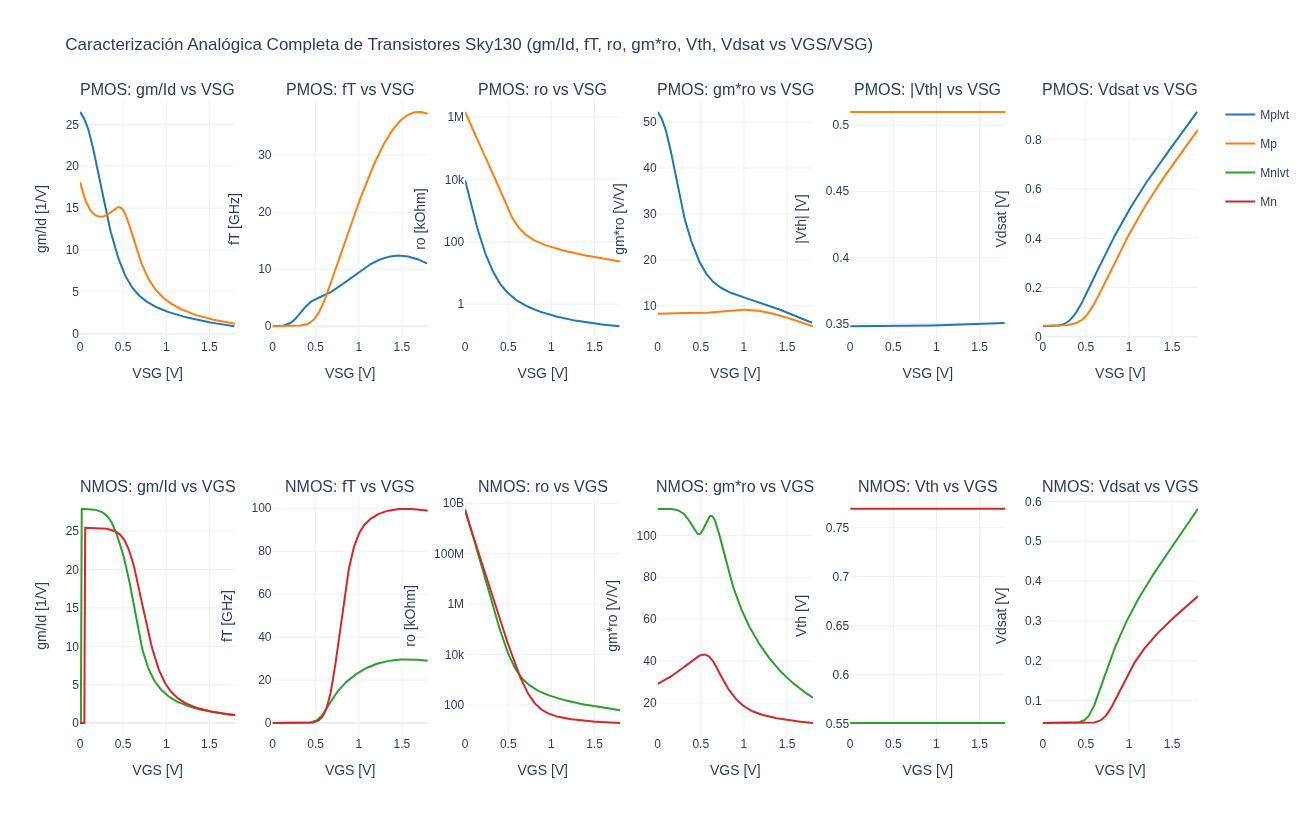

In [3]:
# ==============================================================================
# Encabezado: Generación de Gráficas de Caracterización Interactivas (Plotly)
# Descripción: Dibuja las 6 curvas fundamentales vs VGS/VSG separadas para PMOS y NMOS:
#              Fila 1 (PMOS): gm/Id, fT, ro, gm*ro, Vth, Vdsat vs VSG
#              Fila 2 (NMOS): gm/Id, fT, ro, gm*ro, Vth, Vdsat vs VGS
# ==============================================================================

import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Crear matriz 2x6 (Fila 1: PMOS vs VSG, Fila 2: NMOS vs VGS)
fig = make_subplots(
    rows=2, cols=6,
    subplot_titles=(
        'PMOS: gm/Id vs VSG', 'PMOS: fT vs VSG', 'PMOS: ro vs VSG', 'PMOS: gm*ro vs VSG', 'PMOS: |Vth| vs VSG', 'PMOS: Vdsat vs VSG',
        'NMOS: gm/Id vs VGS', 'NMOS: fT vs VGS', 'NMOS: ro vs VGS', 'NMOS: gm*ro vs VGS', 'NMOS: Vth vs VGS', 'NMOS: Vdsat vs VGS'
    )
)

colors = {
    'Mplvt': '#1f77b4',  # Azul
    'Mp':    '#ff7f0e',  # Naranja
    'Mnlvt': '#2ca02c',  # Verde
    'Mn':    '#d62728'   # Rojo
}

for nombre, info in transistores.items():
    s = info['slice']
    tipo = info['tipo']
    row_idx = 1 if tipo == 'PMOS' else 2
    
    vgs_arr = np.real(abs(raw_data[info['vgs']][s]))
    gm_arr = np.real(abs(raw_data[info['gm']][s]))
    id_arr = np.real(abs(raw_data[info['id']][s]))
    gds_arr = np.real(abs(raw_data[info['gds']][s]))
    cgg_arr = np.real(abs(raw_data[info['cgg']][s]))
    vth_arr = np.real(abs(raw_data[info['vth']][s]))
    vdsat_arr = np.real(abs(raw_data[info['vdsat']][s]))
    
    # Cálculo vectorial de parámetros
    with np.errstate(divide='ignore', invalid='ignore'):
        gm_id_arr = np.where(id_arr > 1e-12, gm_arr / id_arr, 0.0)
        ro_arr = np.where(gds_arr > 1e-15, 1.0 / gds_arr, 0.0)
        gm_ro_arr = gm_arr * ro_arr
        ft_arr = np.where(cgg_arr > 1e-18, gm_arr / (2 * np.pi * cgg_arr), 0.0)
    
    # Col 1: gm/Id vs VGS / VSG
    fig.add_trace(
        go.Scatter(x=vgs_arr, y=gm_id_arr, mode='lines', name=nombre,
                   line=dict(color=colors[nombre], width=2),
                   legendgroup=nombre),
        row=row_idx, col=1
    )
    
    # Col 2: fT (GHz) vs VGS / VSG
    fig.add_trace(
        go.Scatter(x=vgs_arr, y=ft_arr * 1e-9, mode='lines', name=nombre,
                   line=dict(color=colors[nombre], width=2),
                   legendgroup=nombre, showlegend=False),
        row=row_idx, col=2
    )
    
    # Col 3: ro (kOhm) vs VGS / VSG
    fig.add_trace(
        go.Scatter(x=vgs_arr, y=ro_arr * 1e-3, mode='lines', name=nombre,
                   line=dict(color=colors[nombre], width=2),
                   legendgroup=nombre, showlegend=False),
        row=row_idx, col=3
    )
    
    # Col 4: gm*ro (V/V) vs VGS / VSG
    fig.add_trace(
        go.Scatter(x=vgs_arr, y=gm_ro_arr, mode='lines', name=nombre,
                   line=dict(color=colors[nombre], width=2),
                   legendgroup=nombre, showlegend=False),
        row=row_idx, col=4
    )

    # Col 5: Vth (V) vs VGS / VSG
    fig.add_trace(
        go.Scatter(x=vgs_arr, y=vth_arr, mode='lines', name=nombre,
                   line=dict(color=colors[nombre], width=2),
                   legendgroup=nombre, showlegend=False),
        row=row_idx, col=5
    )

    # Col 6: Vdsat (V) vs VGS / VSG
    fig.add_trace(
        go.Scatter(x=vgs_arr, y=vdsat_arr, mode='lines', name=nombre,
                   line=dict(color=colors[nombre], width=2),
                   legendgroup=nombre, showlegend=False),
        row=row_idx, col=6
    )

# Configuración de etiquetas de ejes X e Y para PMOS (Fila 1)
fig.update_xaxes(title_text="VSG [V]", row=1, col=1)
fig.update_yaxes(title_text="gm/Id [1/V]", row=1, col=1)

fig.update_xaxes(title_text="VSG [V]", row=1, col=2)
fig.update_yaxes(title_text="fT [GHz]", row=1, col=2)

fig.update_xaxes(title_text="VSG [V]", row=1, col=3)
fig.update_yaxes(title_text="ro [kOhm]", type="log", row=1, col=3)

fig.update_xaxes(title_text="VSG [V]", row=1, col=4)
fig.update_yaxes(title_text="gm*ro [V/V]", row=1, col=4)

fig.update_xaxes(title_text="VSG [V]", row=1, col=5)
fig.update_yaxes(title_text="|Vth| [V]", row=1, col=5)

fig.update_xaxes(title_text="VSG [V]", row=1, col=6)
fig.update_yaxes(title_text="Vdsat [V]", row=1, col=6)

# Configuración de etiquetas de ejes X e Y para NMOS (Fila 2)
fig.update_xaxes(title_text="VGS [V]", row=2, col=1)
fig.update_yaxes(title_text="gm/Id [1/V]", row=2, col=1)

fig.update_xaxes(title_text="VGS [V]", row=2, col=2)
fig.update_yaxes(title_text="fT [GHz]", row=2, col=2)

fig.update_xaxes(title_text="VGS [V]", row=2, col=3)
fig.update_yaxes(title_text="ro [kOhm]", type="log", row=2, col=3)

fig.update_xaxes(title_text="VGS [V]", row=2, col=4)
fig.update_yaxes(title_text="gm*ro [V/V]", row=2, col=4)

fig.update_xaxes(title_text="VGS [V]", row=2, col=5)
fig.update_yaxes(title_text="Vth [V]", row=2, col=5)

fig.update_xaxes(title_text="VGS [V]", row=2, col=6)
fig.update_yaxes(title_text="Vdsat [V]", row=2, col=6)

fig.update_layout(
    title_text="Caracterización Analógica Completa de Transistores Sky130 (gm/Id, fT, ro, gm*ro, Vth, Vdsat vs VGS/VSG)",
    height=800, width=1900,
    template="plotly_white"
)

fig.show()